# Retinal OCT Denoising — PSO-optimised Modified Soft-Threshold Wavelet Transform

Implementation of **Subhedar, Urooj & Mahajan (2023)**, *"Retinal Optical Coherence Tomography Image Denoising Using
Modified Soft Thresholding Wavelet Transform"*, Traitement du Signal 40(3), 1179–1185.

**Datasets**

* **Duke SD-OCT 2012** (`Sparsity_SDOCT_DATASET_2012`, default) — the 17-B-scan set of Fang et al. [25] that the paper
  evaluates on. Every case has a noisy **raw** B-scan, a registered frame-**averaged** high-SNR image of the same
  location (used here as the clean reference) and the **MSBTD** result of [25] (the paper's Table 5 baseline).
* **Kaggle Kermany OCT2017** (`paultimothymooney/kermany2018`, optional) — CNV / DME / DRUSEN / NORMAL B-scans with no
  clean reference, so only the paper's noisy-input metrics are available.

**Pipeline (Fig. 2 of the paper)**

```
noisy OCT z ──► log transform ──► 2-D DWT (db2, level 1) ──► LL kept as-is
                                                         └─► LH, HL, HH ──► modified soft threshold (α, β, K)  ◄── PSO (fitness = PSNR)
                                  ◄── inverse log ◄── inverse DWT ◄──┘
```

The log / inverse-log steps are **skipped by default** (`LOG_DOMAIN = True`): the Duke B-scans are already
log-compressed, so taking the log again would apply it twice (section 3).

Compared methods (Tables 1–5): Donoho hard thresholding, Donoho soft thresholding, modified soft thresholding with
hand-picked parameters (Cao et al. [19]), the proposed PSO-tuned modified soft thresholding and MSBTD [25].
Metrics: MSE, PSNR, SSIM and CNR — computed against the noisy input as in the paper, and (Duke) against the averaged
reference.

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pywt
import scipy.io as sio
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import uniform_filter
from skimage.filters import threshold_otsu
from skimage.metrics import structural_similarity
from tqdm.auto import tqdm

## 1. Configuration

Hyper-parameter bounds and PSO sizes follow Section 3 of the paper (α ∈ [0, 0.5], β ∈ [1, 5], K ∈ [1, 1.5],
100 particles, 15 iterations — about 35 s per Duke B-scan). `RUN_REFERENCE_PSO` adds a second PSO run whose fitness is
PSNR against the averaged image instead of the noisy input (Duke only, doubles the run time); see the note in
Section 8 for why that is informative.

In [2]:
DATASET = os.environ.get("OCT_DATASET", "duke")      # "duke" or "kermany"

# Duke SD-OCT 2012
DUKE_DIR = Path(os.environ.get("OCT_DUKE_DIR", "Sparsity_SDOCT_DATASET_2012"))
RUN_REFERENCE_PSO = os.environ.get("OCT_REFERENCE_PSO", "1") == "1"
DEMO_IMAGE = "Image 4"                               # the paper's Fig. 3 uses image 4

# Kaggle Kermany OCT2017. Resolved in this order: OCT_DATA_DIR env var -> ./data -> /kaggle/input -> kagglehub download.
DATA_DIR = os.environ.get("OCT_DATA_DIR")
KAGGLE_DATASET = "paultimothymooney/kermany2018"
SPLIT = "test"                  # "train" / "test" / "val" sub-folder of OCT2017
N_PER_CLASS = int(os.environ.get("OCT_N_PER_CLASS", 5))   # images per class (None = all images in the split)

# Wavelet settings (Section 3)
WAVELET = "db2"
LEVEL = 1
# True: the input is already log-compressed (Duke .tifs, Kermany .jpegs), so the paper's log(1 + z) is skipped.
# False: linear-intensity input, wrapped in log1p / expm1 as in the paper's Fig. 2.
LOG_DOMAIN = os.environ.get("OCT_LOG_DOMAIN", "1") == "1"

# Hyper-parameter search space [19]
BOUNDS = {"alpha": (0.0, 0.5), "beta": (1.0, 5.0), "K": (1.0, 1.5)}

# PSO settings
N_PARTICLES = int(os.environ.get("OCT_N_PARTICLES", 100))
N_ITER = int(os.environ.get("OCT_N_ITER", 15))
PSO_W, PSO_C1, PSO_C2 = 0.7298, 1.49618, 1.49618   # Clerc–Kennedy constriction values

# "Manual" parameters for the non-PSO modified soft-threshold baseline (centre of the search space)
MANUAL_PARAMS = {"alpha": 0.25, "beta": 3.0, "K": 1.25}

SEED = 42
MAX_VAL = 255.0                 # 8-bit images -> 2^B - 1
OUT_DIR = Path("outputs") / DATASET
SAVE_DENOISED = True
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load the dataset

Each row of `images` holds the noisy B-scan (`raw`) and, when the dataset provides them, the averaged reference
(`ref`) and the MSBTD result (`msbtd`).

* **Duke** — only the registered pair in each numbered case folder is used. The `Distant/` and `Unregistered/`
  sub-folders of cases 1 and 2 are other acquisitions whose averaged images are not aligned with the raw scan.
* **Kermany** — on Kaggle, add the *kermany2018* dataset to the notebook and it is found under `/kaggle/input`.
  Locally, point `OCT_DATA_DIR` / `./data` at an extracted copy, or let `kagglehub` download it (~5 GB, needs Kaggle
  API credentials in `~/.kaggle/kaggle.json`).

In [3]:
IMG_EXTS = {".jpeg", ".jpg", ".png", ".tif", ".tiff", ".bmp"}


def list_duke(root=DUKE_DIR):
    rows = []
    for case in sorted((d for d in root.iterdir() if d.is_dir() and d.name.isdigit()), key=lambda d: int(d.name)):
        rows.append({
            "image": f"Image {case.name}",
            "group": "Duke",
            "raw": next(case.glob("*Raw Image.tif")),
            "ref": next(case.glob("*Averaged Image.tif")),
            "msbtd": next(case.glob("*MSBTD*.mat"), None),   # "*_MSBTD result.mat" or "*_MSBTD result_result.mat"
        })
    return pd.DataFrame(rows)


def locate_kermany(data_dir=None):
    if data_dir:
        return Path(data_dir)
    if Path("data").exists():
        return Path("data")
    if Path("/kaggle/input").exists():
        return Path("/kaggle/input")
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_DATASET))


def list_kermany(root, split=SPLIT, n_per_class=N_PER_CLASS, seed=SEED):
    # The Kaggle archive ships the same files twice (OCT2017/ and oct2017/OCT2017/), so de-duplicate by file name.
    by_class = {}
    for p in sorted(root.rglob("*")):
        if p.suffix.lower() not in IMG_EXTS or "__MACOSX" in p.parts:
            continue
        if split and p.parent.parent.name.strip().lower() != split:
            continue
        by_class.setdefault(p.parent.name, {}).setdefault(p.name, p)

    rng = np.random.default_rng(seed)
    rows = []
    for cls, files in sorted(by_class.items()):
        paths = list(files.values())
        if n_per_class is not None and len(paths) > n_per_class:
            paths = [paths[i] for i in sorted(rng.choice(len(paths), n_per_class, replace=False))]
        rows += [{"image": f"{cls}/{p.stem}", "group": cls, "raw": p, "ref": None, "msbtd": None} for p in paths]
    return pd.DataFrame(rows)


def load_gray(path):
    return np.asarray(Image.open(path).convert("L"), dtype=np.float64)


def load_msbtd(path):
    mat = sio.loadmat(path)
    return next(v for k, v in mat.items() if not k.startswith("__")).astype(np.float64)


def optional(row, col, loader):
    return loader(row[col]) if isinstance(row[col], Path) else None


if DATASET == "duke":
    images = list_duke()
    print(f"Duke SD-OCT 2012: {len(images)} cases from {DUKE_DIR.resolve()}")
else:
    root = locate_kermany(DATA_DIR)
    images = list_kermany(root)
    print(f"Kermany OCT2017 ({root}): {len(images)} images from split '{SPLIT}'")
    print(images["group"].value_counts().sort_index().to_string())

images.assign(raw=images["raw"].map(lambda p: p.name), ref=images["ref"].map(lambda p: getattr(p, "name", None)),
              msbtd=images["msbtd"].map(lambda p: getattr(p, "name", None)))

Duke SD-OCT 2012: 17 cases from C:\Users\sidhe\OneDrive\Desktop\Acads\Semester-5\Digital_Signal_Processing\Mini_Project\Wavelet_Transform\Sparsity_SDOCT_DATASET_2012


,image,group,raw,ref,msbtd
0,Image 1,Duke,1_Raw Image.tif,1_Averaged Image.tif,1_MSBTD result.mat
1,Image 2,Duke,2_R_Raw Image.tif,2_R_Averaged Image.tif,R_2_MSBTD result.mat
2,Image 3,Duke,3_Raw Image.tif,3_Averaged Image.tif,R_3_MSBTD result.mat
3,Image 4,Duke,4_Raw Image.tif,4_Averaged Image.tif,4_MSBTD result.mat
4,Image 5,Duke,5_Raw Image.tif,5_Averaged Image.tif,5_MSBTD result.mat
5,Image 6,Duke,6_Raw Image.tif,6_Averaged Image.tif,6_MSBTD result_result.mat
6,Image 7,Duke,7_Raw Image.tif,7_Averaged Image.tif,7_MSBTD result_result.mat
7,Image 8,Duke,8_Raw Image.tif,8_Averaged Image.tif,8_MSBTD result_result.mat
8,Image 9,Duke,9_Raw Image.tif,9_Averaged Image.tif,R_9_MSBTD result_result.mat
9,Image 10,Duke,10_Raw Image.tif,10_Averaged Image.tif,R_10_MSBTD result_result.mat


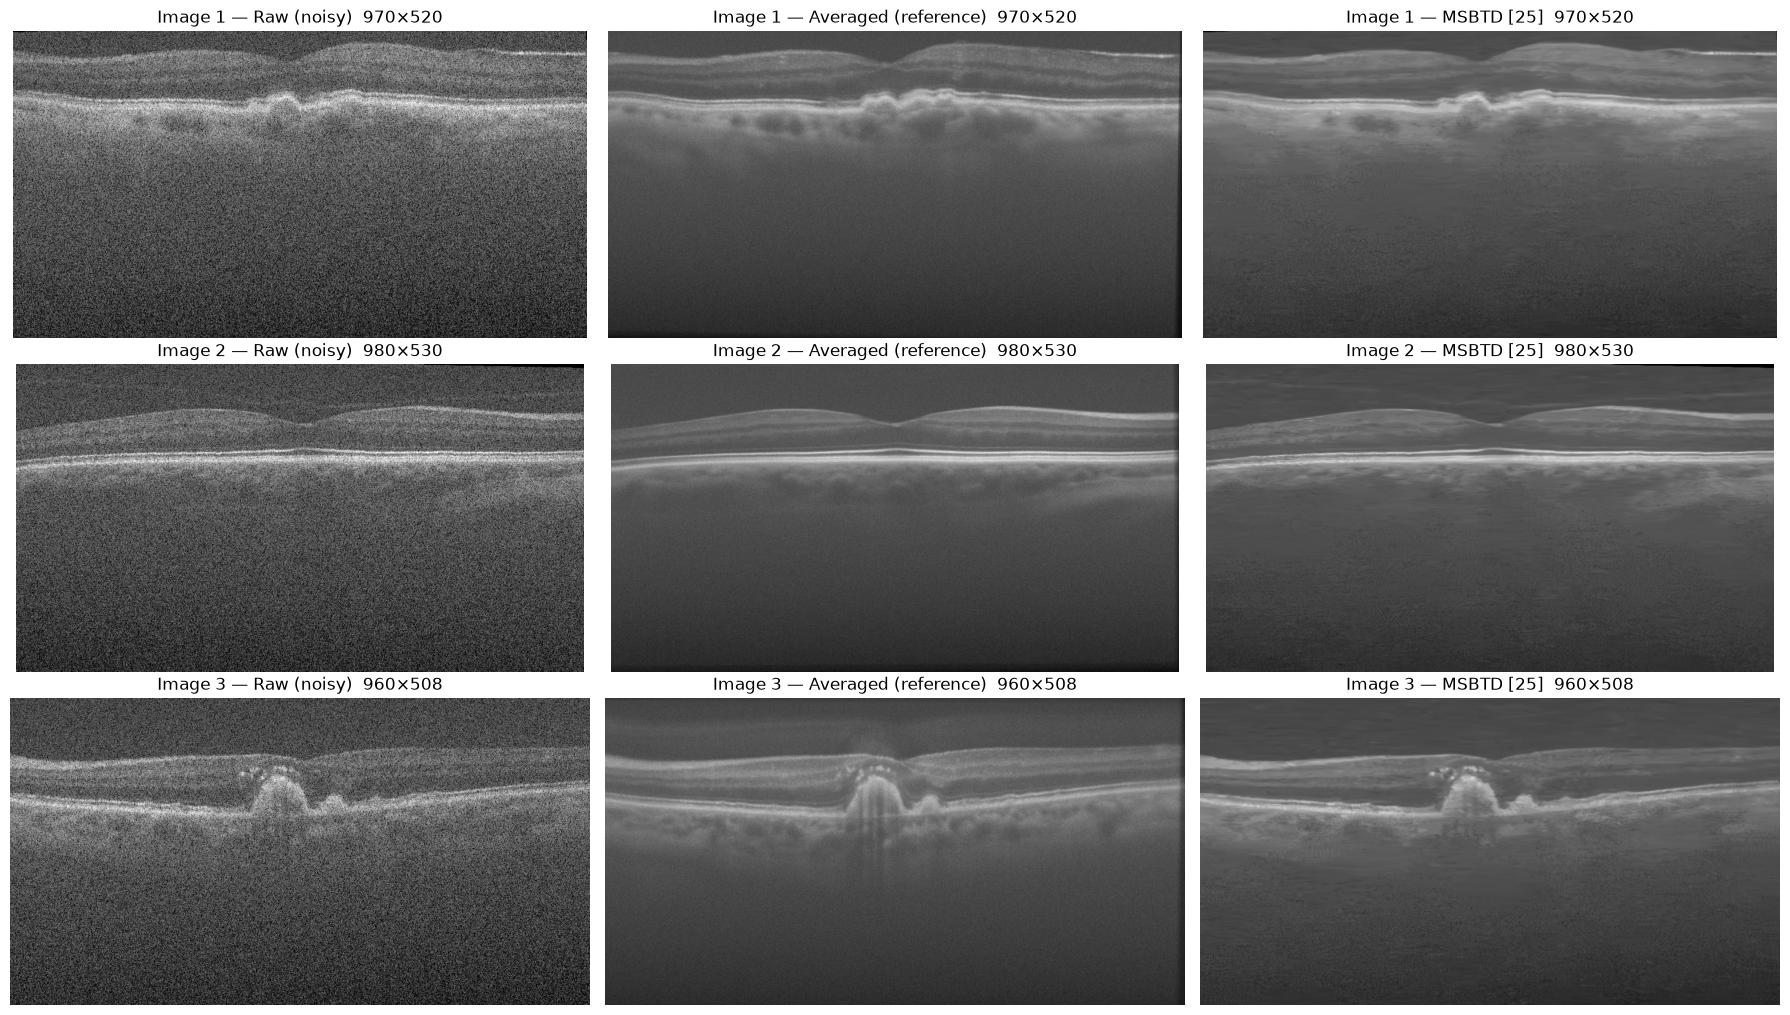

In [4]:
show = images.head(3) if DATASET == "duke" else images.groupby("group").head(1)
cols = [c for c in ["raw", "ref", "msbtd"] if images[c].map(lambda p: isinstance(p, Path)).any()]
titles = {"raw": "Raw (noisy)", "ref": "Averaged (reference)", "msbtd": "MSBTD [25]"}
loaders = {"raw": load_gray, "ref": load_gray, "msbtd": load_msbtd}

fig, axes = plt.subplots(len(show), len(cols), figsize=(6 * len(cols), 3.4 * len(show)), squeeze=False)
for r, (_, row) in enumerate(show.iterrows()):
    for c, col in enumerate(cols):
        img = loaders[col](row[col])
        axes[r, c].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(f"{row['image']} — {titles[col]}  {img.shape[1]}×{img.shape[0]}")
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()

## 3. Modified soft-threshold wavelet denoiser

**Log transform (skipped for this data).** Speckle is multiplicative, $z = s\cdot n$, so the paper takes $\log(1+z)$
to make it (approximately) additive, and $e^x-1$ after the inverse DWT. That only applies to linear-intensity data.
The Duke B-scans are already log-compressed display images. The noise in `raw − averaged` barely grows with brightness
and is skewed towards dark values, which is the opposite of linear speckle (checked in `Comparison/comparison.ipynb`,
section 1, and in the TGV code's `src/io_utils.py`). The paper's own Fig. 3(b) shows what logging a display image
gives: a washed-out grey picture. A second log squashes the bright layers and stretches the dark background, and the
final $e^x-1$ returns a geometric mean, so the output comes out too dark. In the comparison notebook this cost about
5.6 dB PSNR against the averaged image. `LOG_DOMAIN = True` (the default) therefore thresholds the stored values
directly. Set `OCT_LOG_DOMAIN=0` to reproduce the paper's pipeline.

**Threshold, Eq. (3).**
$$y_{th} = K\,\frac{\operatorname{median}(|HH_1|)}{0.6745}\,\frac{\sqrt{2\ln M}}{L_d}$$
with the noise σ estimated from the finest diagonal sub-band (the paper prints 0.6754 — the MAD constant is 0.6745),
$M$ the number of pixels, and the hierarchical level divisor $L_d = \ln(e + d - 1)$ of Cao et al. [19]
($L_1 = 1$, so for the paper's single-level transform this is the Donoho universal threshold scaled by K).

**Modified threshold function, Eq. (2).** With $x = y - \operatorname{sgn}(y)\,y_{th}$ (the soft-threshold value):
$$\tilde y = \begin{cases} x + \dfrac{2}{\pi}\tan^{-1}\!\Big(\beta\dfrac{x}{y_{th}} + \operatorname{sgn}(y)\,\alpha\Big)\,y_{th}, & |y| \ge y_{th}\\[2mm]
\dfrac{2}{\pi}\tan^{-1}(\alpha)\,y, & |y| < y_{th}\end{cases}$$
The function is continuous at $|y| = y_{th}$, shrinks small coefficients by $\tfrac{2}{\pi}\tan^{-1}\alpha$ instead of
zeroing them, and tends to $y$ for large $|y|$ (no soft-threshold bias). β sets how fast it bends back to $y$.

In [5]:
def noise_sigma(hh1):
    return np.median(np.abs(hh1)) / 0.6745


def universal_threshold(sigma, M, K=1.0, d=1):
    L_d = np.log(np.e + d - 1)
    return K * sigma * np.sqrt(2 * np.log(M)) / L_d


def modified_soft_threshold(y, y_th, alpha, beta):
    s = np.sign(y)
    x = y - s * y_th
    big = x + (2 / np.pi) * np.arctan(beta * x / y_th + s * alpha) * y_th
    small = (2 / np.pi) * np.arctan(alpha) * y
    return np.where(np.abs(y) >= y_th, big, small)


class WaveletDenoiser:
    # The forward DWT is computed once per image; PSO only re-runs threshold + inverse DWT.
    # log_domain=True thresholds the image as stored; False wraps it in log1p / expm1 (paper's Fig. 2).

    def __init__(self, img, wavelet=WAVELET, level=LEVEL, max_val=MAX_VAL, log_domain=LOG_DOMAIN):
        self.img, self.wavelet, self.level, self.max_val = img, wavelet, level, max_val
        self.log_domain = log_domain
        self.dwt_input = img if log_domain else np.log1p(img)
        self.coeffs = pywt.wavedec2(self.dwt_input, wavelet, level=level)
        self.sigma = noise_sigma(self.coeffs[-1][2])     # HH of level 1
        self.M = img.size

    def _reconstruct(self, shrink):
        # coeffs = [LL_n, (LH_n, HL_n, HH_n), ..., (LH_1, HL_1, HH_1)]; detail tuple k belongs to level d = n - k + 1
        new = [self.coeffs[0]]
        for k, details in enumerate(self.coeffs[1:]):
            d = self.level - k
            new.append(tuple(shrink(c, d) for c in details))
        rec = pywt.waverec2(new, self.wavelet)[: self.img.shape[0], : self.img.shape[1]]
        return np.clip(rec if self.log_domain else np.expm1(rec), 0, self.max_val)

    def donoho(self, mode):
        return self._reconstruct(lambda c, d: pywt.threshold(c, universal_threshold(self.sigma, self.M), mode=mode))

    def modified(self, alpha, beta, K):
        return self._reconstruct(
            lambda c, d: modified_soft_threshold(c, universal_threshold(self.sigma, self.M, K, d), alpha, beta))

## 4. Particle Swarm Optimisation of (α, β, K)

Each particle $P_i = \{\alpha_i, \beta_i, K_i\}$ (Eq. 4). Following the paper's algorithm, every particle is evaluated,
its personal best and the global best are updated, and its velocity/position are updated with Eqs. (6)–(11):
$$v^{t+1} = w\,v^t + c_1 r_1 (P_{best} - p^t) + c_2 r_2 (G_{best} - p^t), \qquad p^{t+1} = p^t + v^{t+1}$$
Positions are clipped to the bounds and velocities to 20 % of each range. **Fitness (Eq. 5) is the PSNR between the
noisy input image and the reconstruction**, exactly as in the paper. `pso_denoise(img, target=ref)` swaps the
noisy image for the averaged reference in the fitness.

In [6]:
def psnr(ref, img, max_val=MAX_VAL):
    mse = np.mean((ref - img) ** 2)
    return np.inf if mse == 0 else 20 * np.log10(max_val / np.sqrt(mse))


def pso_optimize(fitness, bounds, n_particles=N_PARTICLES, n_iter=N_ITER,
                 w=PSO_W, c1=PSO_C1, c2=PSO_C2, seed=SEED):
    names = list(bounds)
    lo, hi = np.array([bounds[k] for k in names]).T
    v_max = 0.2 * (hi - lo)
    rng = np.random.default_rng(seed)

    pos = rng.uniform(lo, hi, size=(n_particles, len(names)))
    vel = rng.uniform(-v_max, v_max, size=pos.shape)
    pbest_pos, pbest_fit = pos.copy(), np.full(n_particles, -np.inf)
    gbest_pos, gbest_fit = pos[0].copy(), -np.inf
    history = []

    for _ in range(n_iter):
        for i in range(n_particles):
            fit = fitness(**dict(zip(names, pos[i])))
            if fit > pbest_fit[i]:
                pbest_fit[i], pbest_pos[i] = fit, pos[i].copy()
            if fit > gbest_fit:
                gbest_fit, gbest_pos = fit, pos[i].copy()
            r1, r2 = rng.random(len(names)), rng.random(len(names))
            vel[i] = w * vel[i] + c1 * r1 * (pbest_pos[i] - pos[i]) + c2 * r2 * (gbest_pos - pos[i])
            vel[i] = np.clip(vel[i], -v_max, v_max)
            pos[i] = np.clip(pos[i] + vel[i], lo, hi)
        history.append(gbest_fit)

    return dict(zip(names, gbest_pos)), gbest_fit, history


def pso_denoise(img, target=None, **pso_kwargs):
    target = img if target is None else target
    den = WaveletDenoiser(img)
    params, best_fit, history = pso_optimize(lambda **p: psnr(target, den.modified(**p)), BOUNDS, **pso_kwargs)
    return den.modified(**params), params, history

## 5. Performance metrics

* **MSE / PSNR / SSIM (paper protocol)** — between the noisy input $z$ and the denoised image $d$,
  $\text{PSNR} = 20\log_{10}\frac{2^B-1}{\sqrt{MSE}}$. SSIM as in the paper's MATLAB `ssim` call: Gaussian window with
  radius (σ) 2 and the dynamic range taken from the denoised image.
* **MSE_ref / PSNR_ref / SSIM_ref** — the same formulas against the Duke averaged image, i.e. how close the result is
  to the speckle-free scan. This is also how the MSBTD numbers quoted in the paper's Table 5 were obtained [15, 25].
* **CNR** — $\frac{1}{F}\sum_f \frac{|\mu_f-\mu_b|}{\sqrt{\sigma_f^2+\sigma_b^2}}$. The paper prints $\sqrt{|\sigma_f^2-\sigma_b^2|}$ and its
  Table 4 repeats the SSIM numbers, so the standard OCT definition (Fang et al. [25]) is used instead. There are no
  hand-drawn ROIs, so they are picked automatically from a smoothed copy of the averaged image (or of the noisy scan
  when there is no reference): the darkest window above the retina (located by an Otsu threshold) is the background
  (vitreous) and the `F` brightest non-overlapping windows are foreground (RPE / NFL). Constant (padding) windows are skipped. The same ROIs are used for every method
  on a given image.

In [7]:
def ssim(ref, img):
    return structural_similarity(ref, img, data_range=img.max() - img.min(), gaussian_weights=True, sigma=2.0,
                                 use_sample_covariance=False)


def select_rois(img, win=24, n_fg=5):
    # Windows on a grid, scored by their mean; padding (constant or saturated) windows are discarded.
    # The background must lie in the vitreous, i.e. above the retina's upper edge (first Otsu-bright row per column).
    h, w = img.shape
    bright = uniform_filter(img, 15) > threshold_otsu(img)
    retina_top = np.where(bright.any(axis=0), bright.argmax(axis=0), h)
    wins, vitreous = [], []
    for r in range(0, h - win + 1, win):
        for c in range(0, w - win + 1, win):
            patch = img[r:r + win, c:c + win]
            if patch.std() < 1e-3 or (patch >= MAX_VAL).mean() > 0.05 or (patch <= 0).mean() > 0.05:
                continue
            wins.append((patch.mean(), r, c))
            if r + win < retina_top[c:c + win].min() - 5:
                vitreous.append((patch.mean(), r, c))
    wins.sort()
    bg = min(vitreous or wins)[1:]
    fg = [rc[1:] for rc in wins[::-1][:n_fg]]
    return bg, fg, win


def cnr(img, rois):
    (rb, cb), fg, win = rois
    b = img[rb:rb + win, cb:cb + win]
    vals = []
    for rf, cf in fg:
        f = img[rf:rf + win, cf:cf + win]
        vals.append(abs(f.mean() - b.mean()) / np.sqrt(f.var() + b.var() + 1e-12))
    return float(np.mean(vals))


def all_metrics(noisy, den, rois, ref=None):
    m = {"MSE": np.mean((noisy - den) ** 2), "PSNR": psnr(noisy, den), "SSIM": ssim(noisy, den), "CNR": cnr(den, rois)}
    if ref is not None:
        m.update({"MSE_ref": np.mean((ref - den) ** 2), "PSNR_ref": psnr(ref, den), "SSIM_ref": ssim(ref, den)})
    return m

## 6. Run every method on one image

`run_methods` produces the outputs compared in the paper's tables for a single B-scan, plus MSBTD and the
reference-fitness PSO variant when the dataset provides what they need.

In [8]:
PSO_PAPER = "PSO based wavelet thresholding"
PSO_REF = "PSO (fitness vs averaged)"
MSBTD = "MSBTD [25]"


def run_methods(z, ref=None, msbtd=None):
    den = WaveletDenoiser(z)
    outputs = {
        "Donoho hard thresholding": den.donoho("hard"),
        "Donoho soft thresholding": den.donoho("soft"),
        "Modified soft thresholding": den.modified(**MANUAL_PARAMS),
    }
    pso_runs = {}
    t0 = time.time()
    outputs[PSO_PAPER], params, hist = pso_denoise(z)
    pso_runs[PSO_PAPER] = {**params, "fitness_PSNR": hist[-1], "time_s": time.time() - t0, "history": hist}
    if ref is not None and RUN_REFERENCE_PSO:
        t0 = time.time()
        outputs[PSO_REF], params, hist = pso_denoise(z, target=ref)
        pso_runs[PSO_REF] = {**params, "fitness_PSNR": hist[-1], "time_s": time.time() - t0, "history": hist}
    if msbtd is not None:
        outputs[MSBTD] = msbtd
    return den, outputs, pso_runs


def rois_for(z, ref=None):
    return select_rois(uniform_filter(ref if ref is not None else z, 5))

## 7. Walk-through on one image (cf. Fig. 3)

In [9]:
demo_row = images[images["image"] == DEMO_IMAGE].iloc[0] if (images["image"] == DEMO_IMAGE).any() else images.iloc[0]
z = load_gray(demo_row["raw"])
z_ref = optional(demo_row, "ref", load_gray)
z_msbtd = optional(demo_row, "msbtd", load_msbtd)

t0 = time.time()
den, demo_out, demo_pso = run_methods(z, z_ref, z_msbtd)
print(f"{demo_row['image']}: all methods took {time.time() - t0:.1f}s")
for name, run in demo_pso.items():
    print(f"  {name}: " + ", ".join(f"{k}={run[k]:.4f}" for k in BOUNDS))

demo_rois = rois_for(z, z_ref)
display(pd.DataFrame({k: all_metrics(z, v, demo_rois, z_ref) for k, v in demo_out.items()}).T.round(4))

Image 4: all methods took 92.9s
  PSO based wavelet thresholding: alpha=0.5000, beta=5.0000, K=1.0000
  PSO (fitness vs averaged): alpha=0.5000, beta=2.2274, K=1.0000


,MSE,PSNR,SSIM,CNR,MSE_ref,PSNR_ref,SSIM_ref
Donoho hard thresholding,1040.6550,17.9577,0.4612,1.9967,1114.9835,17.6581,0.1058
Donoho soft thresholding,1018.8515,18.0497,0.4278,2.1629,981.0787,18.2138,0.1231
Modified soft thresholding,769.0175,19.2714,0.5669,2.1697,935.4800,18.4205,0.1258
PSO based wavelet thresholding,544.4883,20.7709,0.6960,2.1340,905.8158,18.5604,0.1218
PSO (fitness vs averaged),552.2293,20.7096,0.6914,2.1353,904.3823,18.5673,0.1229
MSBTD [25],802.9770,19.0838,0.2326,4.0455,180.0381,25.5772,0.5317


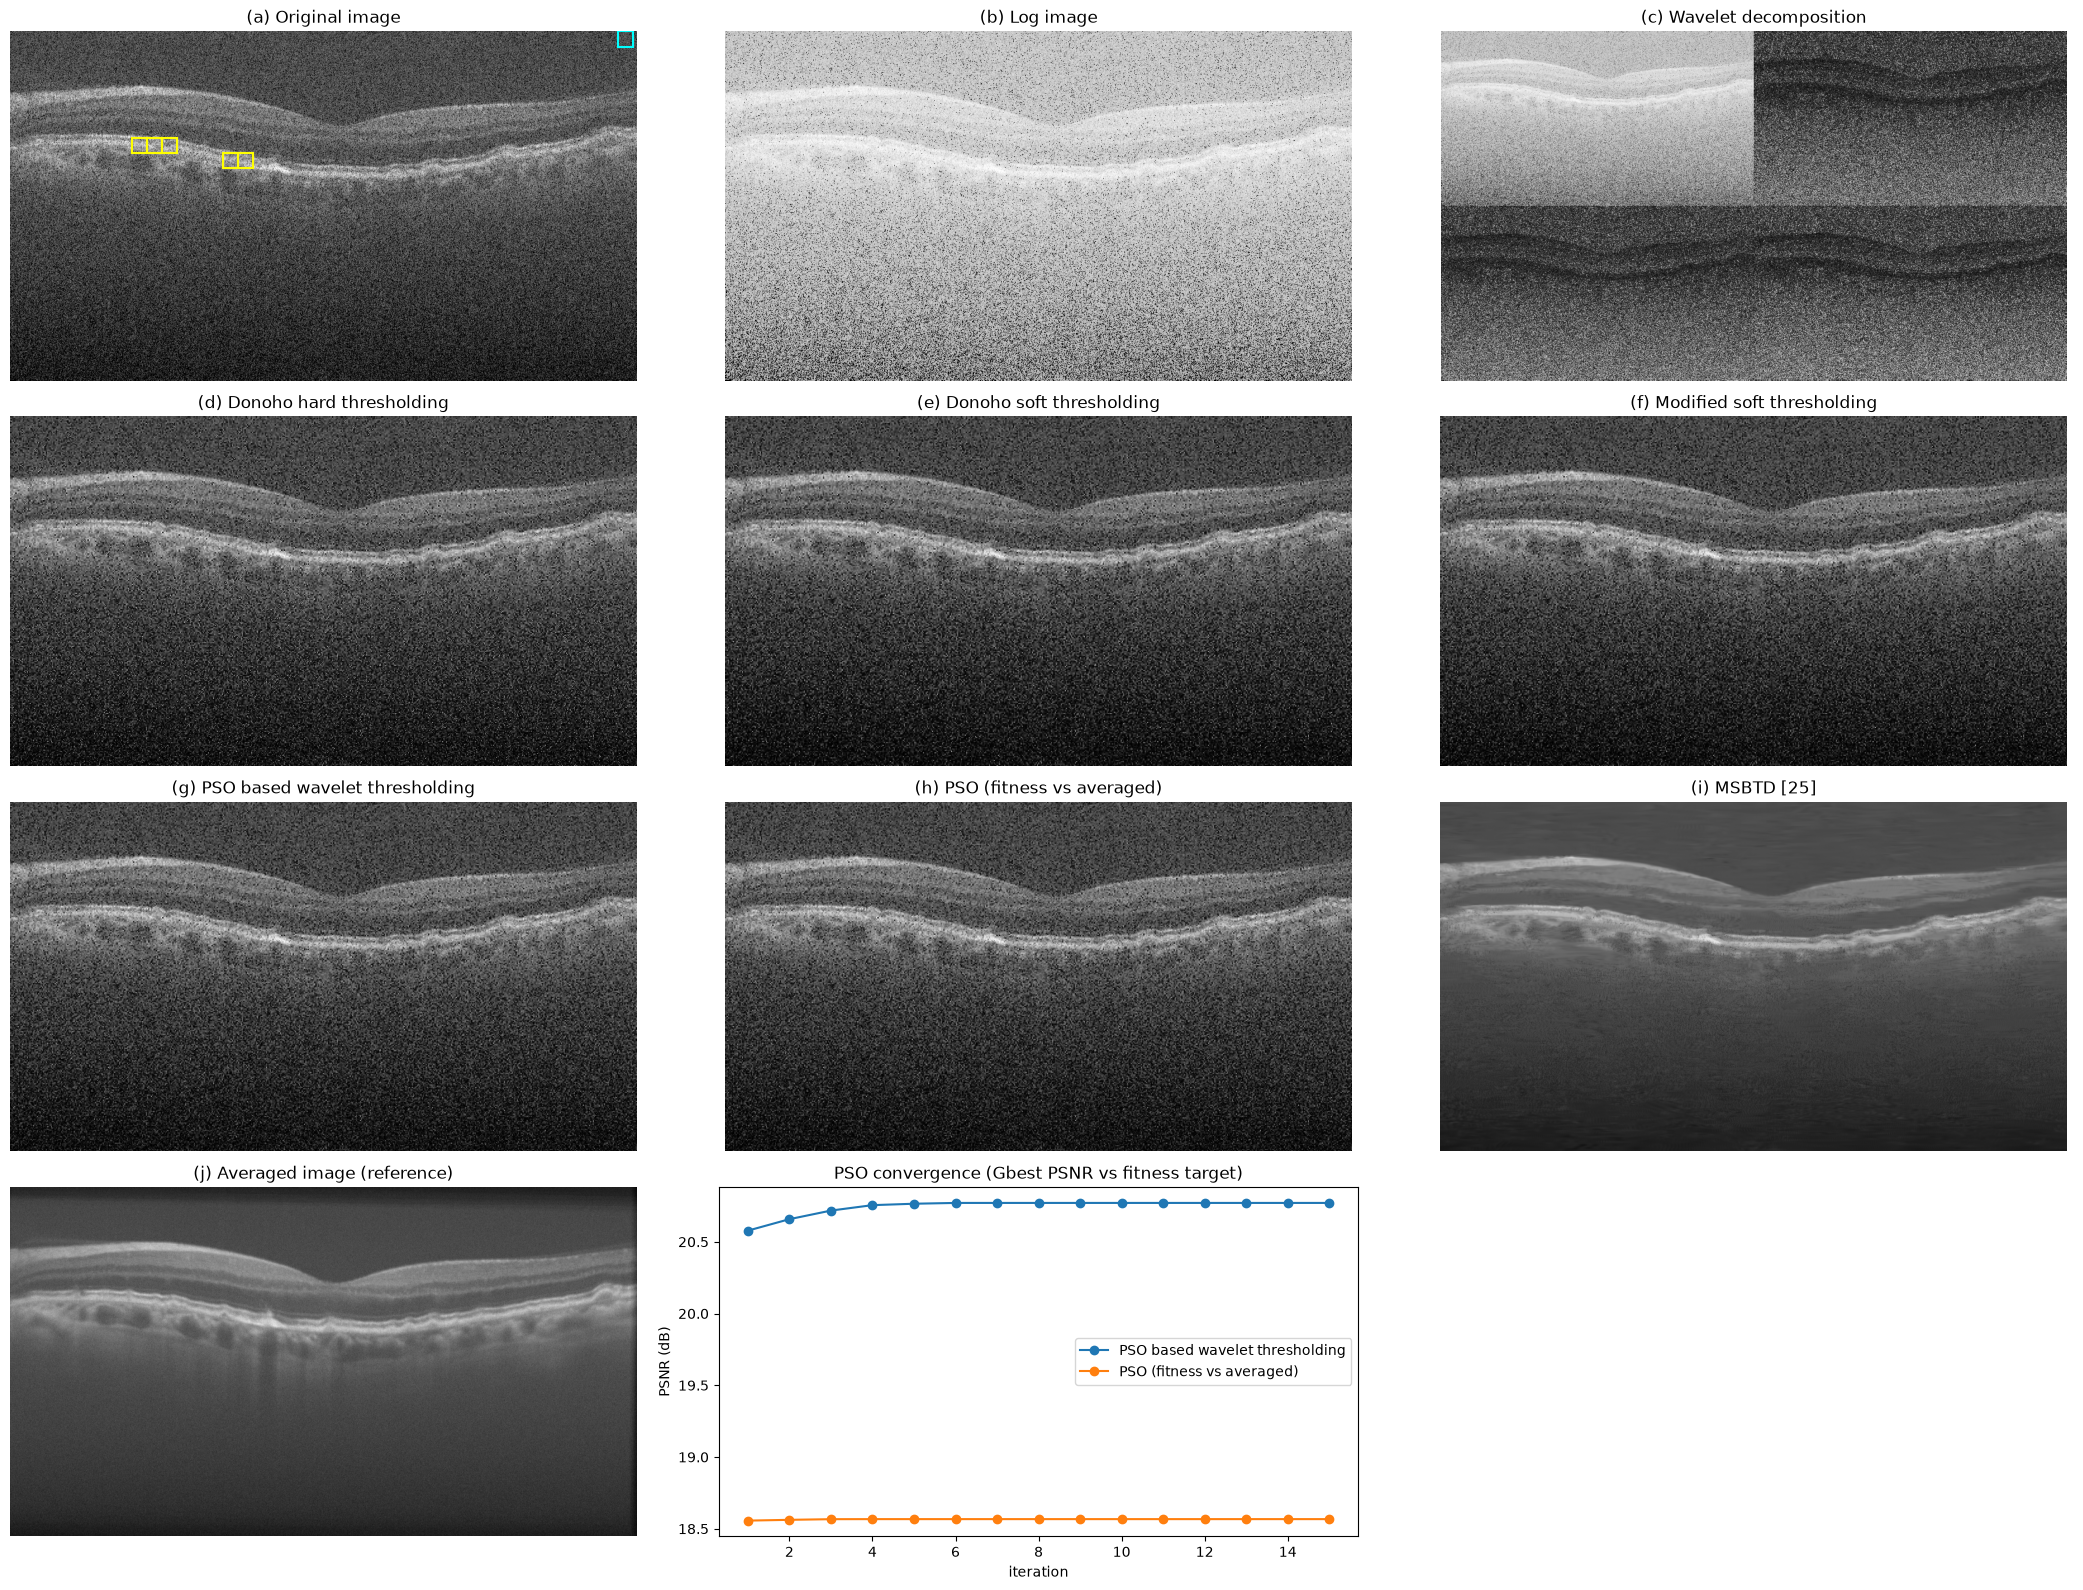

In [10]:
LL, (LH, HL, HH) = den.coeffs
norm = lambda a: (np.abs(a) - np.abs(a).min()) / (np.ptp(np.abs(a)) + 1e-12)
decomp = np.block([[norm(LL), norm(LH) ** 0.5], [norm(HL) ** 0.5, norm(HH) ** 0.5]])

# (title, image, shown on the fixed 0-255 intensity scale)
log_title = "log(1 + z), paper's Fig. 3(b), not applied" if den.log_domain else "Log image"
panels = [("Original image", z, True), (log_title, np.log1p(z), False), ("Wavelet decomposition", decomp, False)]
panels += [(name, img, True) for name, img in demo_out.items()]
if z_ref is not None:
    panels.append(("Averaged image (reference)", z_ref, True))
panels = [(f"({chr(ord('a') + i)}) {t}", im, fixed) for i, (t, im, fixed) in enumerate(panels)]

n_cols = 3
n_rows = int(np.ceil((len(panels) + 1) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 4 * n_rows))
for ax, (title, im, fixed) in zip(axes.flat, panels):
    ax.imshow(im, cmap="gray", **({"vmin": 0, "vmax": MAX_VAL} if fixed else {}))
    ax.set_title(title)
    ax.axis("off")
(rb, cb), fg, win = demo_rois
axes.flat[0].add_patch(plt.Rectangle((cb, rb), win, win, fill=False, ec="cyan", lw=1.5))
for rf, cf in fg:
    axes.flat[0].add_patch(plt.Rectangle((cf, rf), win, win, fill=False, ec="yellow", lw=1.5))
ax = axes.flat[len(panels)]
for name, run in demo_pso.items():
    ax.plot(range(1, len(run["history"]) + 1), run["history"], marker="o", label=name)
ax.set(title="PSO convergence (Gbest PSNR vs fitness target)", xlabel="iteration", ylabel="PSNR (dB)")
ax.legend()
for ax in axes.flat[len(panels) + 1:]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig3_walkthrough.png", dpi=110)
plt.show()

## 8. Run all methods on every image (Tables 1–5)

In [ ]:
records, pso_params = [], []
if SAVE_DENOISED:
    (OUT_DIR / "denoised").mkdir(exist_ok=True)

for _, row in tqdm(list(images.iterrows()), desc="images"):
    z = load_gray(row["raw"])
    ref = optional(row, "ref", load_gray)
    msbtd = optional(row, "msbtd", load_msbtd)
    _, outputs, pso_runs = run_methods(z, ref, msbtd)
    rois = rois_for(z, ref)

    for method, d in outputs.items():
        records.append({"image": row["image"], "group": row["group"], "method": method,
                        **all_metrics(z, d, rois, ref)})
    for method, run in pso_runs.items():
        pso_params.append({"image": row["image"], "group": row["group"], "variant": method,
                           **{k: v for k, v in run.items() if k != "history"}})

    if SAVE_DENOISED:
        stem = row["image"].replace("/", "_").replace(" ", "_")
        for method, tag in [(PSO_PAPER, "pso"), (PSO_REF, "pso_ref")]:
            if method in outputs:
                Image.fromarray(np.round(outputs[method]).astype(np.uint8)).save(
                    OUT_DIR / "denoised" / f"{stem}_{tag}.png")

results = pd.DataFrame(records)
params_df = pd.DataFrame(pso_params)
results.to_csv(OUT_DIR / "metrics_per_image.csv", index=False)
params_df.to_csv(OUT_DIR / "pso_params_per_image.csv", index=False)

method_order = [m for m in ["Donoho hard thresholding", "Donoho soft thresholding", "Modified soft thresholding",
                            PSO_PAPER, PSO_REF, MSBTD] if m in set(results["method"])]

In [8]:
# Reload the loop's saved results when the kernel was restarted, so the cells below work without re-running PSO.
if "results" not in globals():
    results = pd.read_csv(OUT_DIR / "metrics_per_image.csv")
    params_df = pd.read_csv(OUT_DIR / "pso_params_per_image.csv")
    method_order = [m for m in ["Donoho hard thresholding", "Donoho soft thresholding", "Modified soft thresholding",
                                PSO_PAPER, PSO_REF, MSBTD] if m in set(results["method"])]
    print(f"Loaded saved results from {OUT_DIR}: {results['image'].nunique()} images, {len(method_order)} methods")
else:
    print(f"Using results from the run above: {results['image'].nunique()} images, {len(method_order)} methods")

Loaded saved results from outputs\duke: 17 images, 6 methods


### Tables 1–4 — paper protocol (metrics against the noisy input)

In [9]:
def per_image_table(metric):
    table = results.pivot(index="image", columns="method", values=metric)[method_order]
    table = table.loc[results["image"].unique()]
    table.loc[f"Mean {metric}"] = table.mean()
    return table


for metric in ["MSE", "PSNR", "SSIM", "CNR"]:
    print(f"\n=== Performance parameter: {metric} (vs noisy input) ===")
    display(per_image_table(metric).round(4))


=== Performance parameter: MSE (vs noisy input) ===


method,Donoho hard thresholding,Donoho soft thresholding,Modified soft thresholding,PSO based wavelet thresholding,PSO (fitness vs averaged),MSBTD [25]
image,,,,,,
Image 1,1188.1997,1105.9828,834.3574,574.7107,622.6720,914.7901
Image 2,1058.6032,984.5369,741.6488,510.0693,549.7602,813.5207
Image 3,1062.3919,993.2849,749.1203,516.1442,533.2111,812.8902
Image 4,1040.6550,1018.8515,769.0175,544.4883,552.2293,802.9770
Image 5,885.2457,891.7623,674.2475,493.2135,493.2135,725.8316
Image 6,992.4189,977.4635,734.0198,520.3393,532.3484,825.3766
Image 7,988.1175,961.3867,723.2212,510.2417,528.5811,768.6163
Image 8,974.3823,964.2140,725.3513,519.3907,535.1790,744.1233
Image 9,1065.1122,1041.7633,784.8309,552.5346,561.3765,712.3097



=== Performance parameter: PSNR (vs noisy input) ===


method,Donoho hard thresholding,Donoho soft thresholding,Modified soft thresholding,PSO based wavelet thresholding,PSO (fitness vs averaged),MSBTD [25]
image,,,,,,
Image 1,17.3819,17.6933,18.9173,20.5363,20.1882,18.5176
Image 2,17.8835,18.1985,19.4288,21.0545,20.7291,19.0271
Image 3,17.8680,18.1601,19.3853,21.0031,20.8618,19.0305
Image 4,17.9577,18.0497,19.2714,20.7709,20.7096,19.0838
Image 5,18.6602,18.6283,19.8426,21.2005,21.2005,19.5224
Image 6,18.1639,18.2298,19.4737,20.9679,20.8688,18.9643
Image 7,18.1827,18.3018,19.5381,21.0530,20.8997,19.2737
Image 8,18.2435,18.2891,19.5253,20.9759,20.8458,19.4144
Image 9,17.8568,17.9531,19.1830,20.7072,20.6383,19.6041



=== Performance parameter: SSIM (vs noisy input) ===


method,Donoho hard thresholding,Donoho soft thresholding,Modified soft thresholding,PSO based wavelet thresholding,PSO (fitness vs averaged),MSBTD [25]
image,,,,,,
Image 1,0.4760,0.4503,0.5866,0.7186,0.6969,0.2281
Image 2,0.4768,0.4525,0.5886,0.7203,0.7003,0.2367
Image 3,0.4747,0.4483,0.5846,0.7169,0.7078,0.2200
Image 4,0.4612,0.4278,0.5669,0.6960,0.6914,0.2326
Image 5,0.4177,0.3967,0.5442,0.6703,0.6703,0.1998
Image 6,0.4687,0.4413,0.5805,0.7048,0.6984,0.1845
Image 7,0.4625,0.4334,0.5748,0.7032,0.6931,0.2105
Image 8,0.4576,0.4324,0.5732,0.6971,0.6884,0.2433
Image 9,0.4840,0.4538,0.5869,0.7109,0.7061,0.3456



=== Performance parameter: CNR (vs noisy input) ===


method,Donoho hard thresholding,Donoho soft thresholding,Modified soft thresholding,PSO based wavelet thresholding,PSO (fitness vs averaged),MSBTD [25]
image,,,,,,
Image 1,2.0609,2.2651,2.3019,2.2539,2.2870,3.8824
Image 2,1.7556,1.8562,1.8672,1.8513,1.8585,2.3194
Image 3,2.1403,2.3373,2.3593,2.3314,2.3414,4.3803
Image 4,1.9967,2.1629,2.1697,2.1340,2.1353,4.0455
Image 5,2.8611,2.8938,2.9788,2.9791,2.9791,7.0584
Image 6,1.8846,1.9986,2.0161,2.0038,2.0065,3.3205
Image 7,2.2648,2.3332,2.3627,2.3398,2.3462,4.4894
Image 8,2.1976,2.2235,2.2520,2.2438,2.2435,3.5826
Image 9,1.4390,1.4894,1.5003,1.4988,1.4976,2.0458


### Reference-based metrics (against the averaged image)

Only available for the Duke dataset. These measure actual speckle removal: a method that returns the noisy image
unchanged scores perfectly on the paper-protocol PSNR, but scores only as well as the raw scan does here.

In [10]:
if "PSNR_ref" in results:
    for metric in ["MSE_ref", "PSNR_ref", "SSIM_ref"]:
        print(f"\n=== {metric} (vs averaged image) ===")
        display(per_image_table(metric).round(4))

    raw_vs_ref = pd.DataFrame([{"PSNR_ref": psnr(load_gray(r["ref"]), load_gray(r["raw"])),
                                "SSIM_ref": ssim(load_gray(r["ref"]), load_gray(r["raw"]))}
                               for _, r in images.iterrows()]).mean()
    print("Raw noisy scan vs averaged image (no denoising):", raw_vs_ref.round(4).to_dict())
else:
    print("No reference images in this dataset — reference-based metrics skipped.")


=== MSE_ref (vs averaged image) ===


method,Donoho hard thresholding,Donoho soft thresholding,Modified soft thresholding,PSO based wavelet thresholding,PSO (fitness vs averaged),MSBTD [25]
image,,,,,,
Image 1,1179.7737,855.4255,808.6913,823.5298,789.2177,136.2677
Image 2,1031.0286,752.9407,710.1829,717.4543,692.3678,102.0982
Image 3,1108.3986,875.8772,830.5389,818.2447,805.1985,111.5462
Image 4,1114.9835,981.0787,935.4800,905.8158,904.3823,180.0381
Image 5,870.4304,838.2008,805.4084,780.9033,780.9033,130.3114
Image 6,963.8667,832.1771,783.6754,758.0932,754.9916,105.5218
Image 7,870.3538,701.0927,658.5159,644.7844,638.7089,65.4896
Image 8,816.4160,692.2929,649.0134,634.4878,629.8571,89.2328
Image 9,1317.3486,1178.2201,1126.3577,1091.0559,1089.3264,324.8010



=== PSNR_ref (vs averaged image) ===


method,Donoho hard thresholding,Donoho soft thresholding,Modified soft thresholding,PSO based wavelet thresholding,PSO (fitness vs averaged),MSBTD [25]
image,,,,,,
Image 1,17.4128,18.8090,19.0530,18.9740,19.1588,26.7869
Image 2,17.9981,19.3632,19.6171,19.5729,19.7274,28.0406
Image 3,17.6838,18.7064,18.9372,19.0020,19.0718,27.6563
Image 4,17.6581,18.2138,18.4205,18.5604,18.5673,25.5772
Image 5,18.7335,18.8973,19.0706,19.2048,19.2048,26.9810
Image 6,18.2906,18.9286,19.1894,19.3336,19.3514,27.8974
Image 7,18.7338,19.6730,19.9451,20.0367,20.0778,29.9691
Image 8,19.0117,19.7279,20.0083,20.1066,20.1384,28.6256
Image 9,16.9338,17.4185,17.6140,17.7523,17.7592,23.0146



=== SSIM_ref (vs averaged image) ===


method,Donoho hard thresholding,Donoho soft thresholding,Modified soft thresholding,PSO based wavelet thresholding,PSO (fitness vs averaged),MSBTD [25]
image,,,,,,
Image 1,0.0968,0.1173,0.1189,0.1114,0.1161,0.5123
Image 2,0.1168,0.1402,0.1426,0.1351,0.1398,0.5949
Image 3,0.1026,0.1252,0.1277,0.1214,0.1246,0.4788
Image 4,0.1058,0.1231,0.1258,0.1218,0.1229,0.5317
Image 5,0.1341,0.1434,0.1455,0.1407,0.1407,0.5864
Image 6,0.0950,0.1095,0.1129,0.1105,0.1117,0.5247
Image 7,0.1183,0.1367,0.1396,0.1352,0.1369,0.4889
Image 8,0.1292,0.1437,0.1471,0.1434,0.1448,0.6151
Image 9,0.0943,0.1092,0.1119,0.1095,0.1104,0.3720


Raw noisy scan vs averaged image (no denoising): {'PSNR_ref': 17.7437, 'SSIM_ref': 0.0836}


### Summary and comparison with the paper's reported means (Tables 1–3 and 5)

The paper's Table 5 MSBTD values (PSNR 26.46, SSIM 0.56) are taken from [15], where they are computed against the
averaged image, whereas its Tables 1–3 are computed against the noisy input — so the two should be compared with the
`_ref` and the plain columns respectively.

In [11]:
metric_cols = [c for c in ["MSE", "PSNR", "SSIM", "CNR", "MSE_ref", "PSNR_ref", "SSIM_ref"] if c in results]
summary = results.groupby("method")[metric_cols].mean().loc[method_order]
summary.to_csv(OUT_DIR / "metrics_summary.csv")
print("Mean over all images (this implementation)")
display(summary.round(4))

paper = pd.DataFrame({
    "MSE": [323.35, 185.67, 144.3835, 142.6048, np.nan],
    "PSNR": [23.06, 25.46, 26.5552, 26.6088, np.nan],
    "SSIM": [0.52, 0.61, 0.6490, 0.6570, np.nan],
    "PSNR_ref": [np.nan, np.nan, np.nan, np.nan, 26.46],
    "SSIM_ref": [np.nan, np.nan, np.nan, np.nan, 0.56],
}, index=["Donoho hard thresholding", "Donoho soft thresholding", "Modified soft thresholding", PSO_PAPER, MSBTD])
print("Means reported in the paper (Tables 1–3, 5)")
display(paper)

if results["group"].nunique() > 1:
    print("Mean PSNR / SSIM per group")
    display(results.pivot_table(index="group", columns="method", values=["PSNR", "SSIM"])
            .reindex(columns=method_order, level=1).round(4))

Mean over all images (this implementation)


,MSE,PSNR,SSIM,CNR,MSE_ref,PSNR_ref,SSIM_ref
method,,,,,,,
Donoho hard thresholding,1031.5061,18.0029,0.4801,2.3303,1070.2466,17.8707,0.1139
Donoho soft thresholding,979.6909,18.2247,0.4540,2.4453,856.1887,18.8429,0.1335
Modified soft thresholding,736.7140,19.4631,0.5894,2.4668,812.9973,19.0706,0.1358
PSO based wavelet thresholding,514.3532,21.0230,0.7159,2.4396,805.1302,19.1102,0.1299
PSO (fitness vs averaged),539.4479,20.8161,0.7030,2.4502,789.3113,19.1983,0.1332
MSBTD [25],764.1329,19.3177,0.2752,3.7713,152.0432,26.7643,0.5170


Means reported in the paper (Tables 1–3, 5)


,MSE,PSNR,SSIM,PSNR_ref,SSIM_ref
Donoho hard thresholding,323.3500,23.0600,0.520,NaN,NaN
Donoho soft thresholding,185.6700,25.4600,0.610,NaN,NaN
Modified soft thresholding,144.3835,26.5552,0.649,NaN,NaN
PSO based wavelet thresholding,142.6048,26.6088,0.657,NaN,NaN
MSBTD [25],NaN,NaN,NaN,26.46,0.56


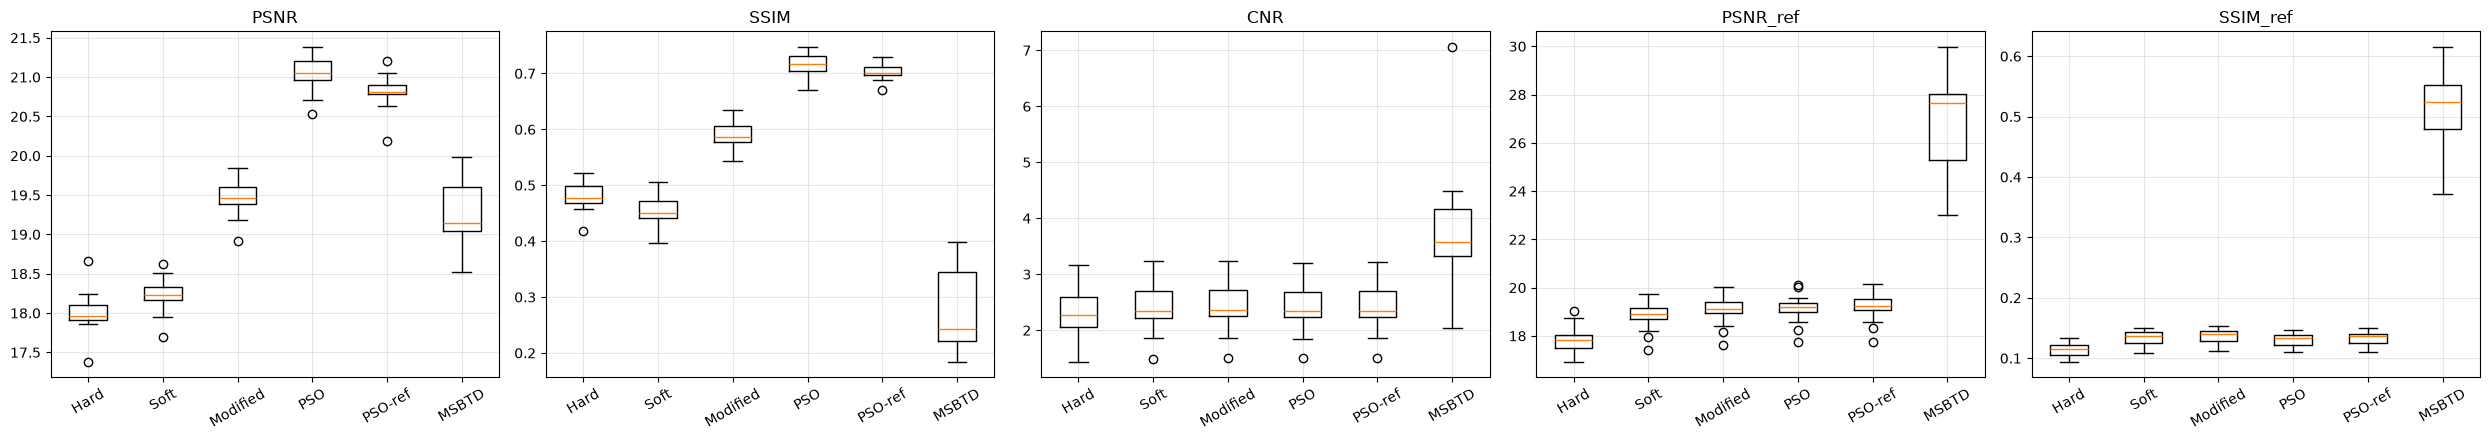

In [12]:
plot_metrics = [c for c in ["PSNR", "SSIM", "CNR", "PSNR_ref", "SSIM_ref"] if c in results]
short = {"Donoho hard thresholding": "Hard", "Donoho soft thresholding": "Soft", "Modified soft thresholding": "Modified",
         PSO_PAPER: "PSO", PSO_REF: "PSO-ref", MSBTD: "MSBTD"}
fig, axes = plt.subplots(1, len(plot_metrics), figsize=(5 * len(plot_metrics), 4.5))
for ax, metric in zip(np.atleast_1d(axes), plot_metrics):
    data = [results.loc[results["method"] == m, metric] for m in method_order]
    ax.boxplot(data, tick_labels=[short[m] for m in method_order])
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "metrics_boxplot.png", dpi=110)
plt.show()

## 9. PSO-selected hyper-parameters

The paper's argument for PSO is that the best (α, β, K) differ from image to image. The table below shows what the
swarm actually picked, together with how often each parameter ended on a boundary of its search range.

In [13]:
display(params_df.round(4))

for variant, grp in params_df.groupby("variant", sort=False):
    print(f"\n{variant}")
    print(grp[["alpha", "beta", "K", "fitness_PSNR", "time_s"]].describe().loc[["mean", "std", "min", "max"]].round(4))
    for name, (lo, hi) in BOUNDS.items():
        at_lo = np.isclose(grp[name], lo, atol=1e-3).mean()
        at_hi = np.isclose(grp[name], hi, atol=1e-3).mean()
        print(f"  {name:>5}: at lower bound {at_lo:5.0%}   at upper bound {at_hi:5.0%}")

,image,group,variant,alpha,beta,K,fitness_PSNR,time_s
0,Image 1,Duke,PSO based wavelet thresholding,0.5,5.0000,1.0000,20.5363,33.5090
1,Image 1,Duke,PSO (fitness vs averaged),0.5,1.0000,1.2558,19.1588,34.3947
2,Image 2,Duke,PSO based wavelet thresholding,0.5,5.0000,1.0000,21.0545,41.9069
3,Image 2,Duke,PSO (fitness vs averaged),0.5,1.0000,1.2313,19.7274,43.7276
4,Image 3,Duke,PSO based wavelet thresholding,0.5,5.0000,1.0000,21.0031,29.6761
5,Image 3,Duke,PSO (fitness vs averaged),0.5,1.0000,1.0171,19.0718,32.8677
6,Image 4,Duke,PSO based wavelet thresholding,0.5,5.0000,1.0000,20.7709,55.9632
7,Image 4,Duke,PSO (fitness vs averaged),0.5,2.2274,1.0000,18.5673,56.7926
8,Image 5,Duke,PSO based wavelet thresholding,0.5,5.0000,1.0000,21.2005,57.2300
9,Image 5,Duke,PSO (fitness vs averaged),0.5,5.0000,1.0000,19.2048,54.0418



PSO based wavelet thresholding
      alpha    beta    K  fitness_PSNR   time_s
mean    0.5  4.7232  1.0       21.0230  44.0528
std     0.0  0.6072  0.0        0.2087   8.9903
min     0.5  2.7557  1.0       20.5363  29.6761
max     0.5  5.0000  1.0       21.3822  57.2300
  alpha: at lower bound    0%   at upper bound  100%
   beta: at lower bound    0%   at upper bound   76%
      K: at lower bound  100%   at upper bound    0%

PSO (fitness vs averaged)
      alpha    beta       K  fitness_PSNR   time_s
mean    0.5  1.3754  1.1289       19.1983  43.6075
std     0.0  1.0095  0.1511        0.5984   7.2581
min     0.5  1.0000  1.0000       17.7592  32.4767
max     0.5  5.0000  1.4677       20.1384  56.7926
  alpha: at lower bound    0%   at upper bound  100%
   beta: at lower bound   76%   at upper bound    6%
      K: at lower bound   35%   at upper bound    0%


### Note on the fitness function

The paper's fitness is PSNR between the **noisy input** and the reconstruction. That quantity is maximised by removing
as little as possible: the smallest threshold (K → 1), the weakest shrinkage of sub-threshold coefficients
(α → 0.5, i.e. scale $\tfrac{2}{\pi}\tan^{-1}0.5 \approx 0.30$ instead of lower) and the fastest return to the identity
above the threshold (β → 5). So the swarm is expected to converge to the corner (α, β, K) = (0.5, 5, 1) of the search
box for every image, which is what the boundary counts above show. The higher paper-protocol PSNR/SSIM of the PSO
column therefore reflects "closest to the noisy input", not "least noise".

The Duke averaged images make this checkable: the `PSO (fitness vs averaged)` variant tunes the same three parameters
for closeness to the speckle-free scan instead. Its parameters, and its `PSNR_ref` / `SSIM_ref`, show what the modified
soft-threshold method can achieve when PSO optimises for denoising quality — an oracle upper bound, since a clean
reference is not available in practice. A deployable alternative would be a reference-free fitness (e.g. CNR/ENL on
background ROIs balanced against an edge-preservation term).